# Model weighted functional inputs

A functional predictor is a measured trajectory rather than a single scalar. A weighted smooth sums a coefficient function across each trajectory to predict the response.

$$\mathbb E[Y_i\mid X_i]=\beta_0+\int X_i(t)\beta(t)\,dt
\approx\beta_0+\sum_\ell q_\ell X_i(t_\ell)\beta(t_\ell).$$

Here $X_i(t_\ell)$ is an observed trajectory, $\beta(t)$ is the coefficient function, and $q_\ell$ approximates integration over the functional domain. These quadrature weights operate within each trajectory; observation/sample weights instead change how much each response row contributes to fitting.

Thin-plate bases `tp` and `ts` also support these weighted matrix inputs. They additionally accept unweighted sums, for example `s(locations, bs="tp", k=10)`, and paired multidimensional location matrices such as `s(X, Z, by=weights, bs="ts", k=10)`. Coordinate matrices and quadrature weights must have matching shapes. Prediction reuses the fitted basis and can use a different number of quadrature points.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from nampy.gam import GAM

rng=np.random.default_rng(109)


## Simulate trajectories and weighted responses

Trapezoidal quadrature approximates the integral of a trajectory times its coefficient function. Location vectors and weighted trajectories are stored as array-valued DataFrame cells.

In [2]:
t=np.linspace(0,1,41)
quadrature=np.full(len(t),1/(len(t)-1));quadrature[[0,-1]]*=.5
coefficients=rng.normal(size=(450,6))
basis=np.array([np.sin(j*np.pi*t) for j in range(1,7)])
trajectories=coefficients@basis
beta=1.2*np.sin(2*np.pi*t)
weighted=trajectories*quadrature
y=weighted@beta+rng.normal(0,.08,len(trajectories))
data=pd.DataFrame({"locations":list(np.tile(t,(len(y),1))),"weights":list(weighted),"y":y})
train,test=train_test_split(data,test_size=.25,random_state=109)
model=GAM(formula="y ~ s(locations,by=weights,bs='ps',k=12)",optimize_smoothing=True,smoothing_method="reml").fit(train)

## Inspect trajectories and the coefficient function

Unit-vector weights extract the coefficient function at each location through the same public prediction interface. Subtracting a zero-weight prediction removes the intercept. The training trajectories span only six sine modes, so recovery outside that span is penalty-dependent.

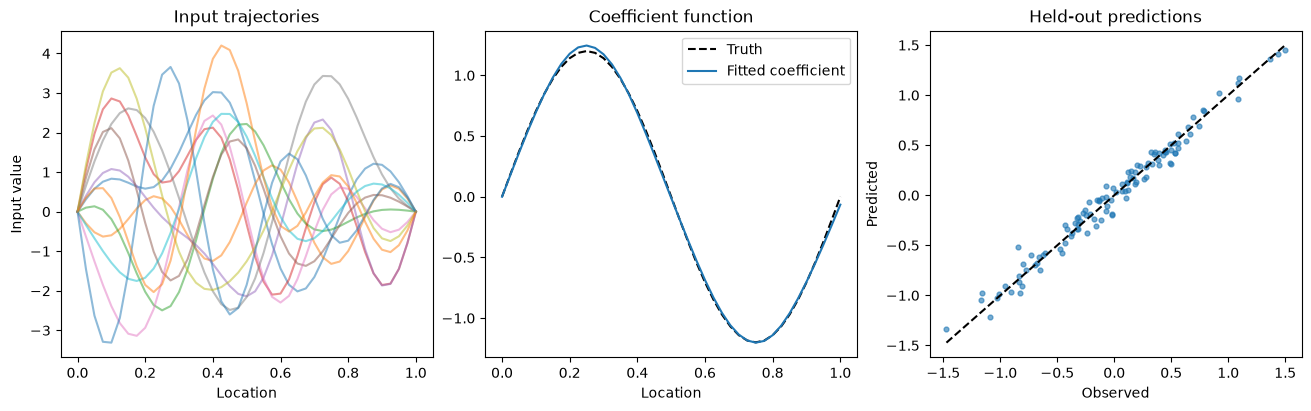

Test RMSE
0.089


In [3]:
unit_weights=np.eye(len(t))
probe=pd.DataFrame({"locations":list(np.tile(t,(len(t),1))),"weights":list(unit_weights)})
zero=probe.copy();zero["weights"]=list(np.zeros_like(unit_weights))
fitted_beta=model.predict(probe)-model.predict(zero)
prediction=model.predict(test)
figure,axes=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
axes[0].plot(t,trajectories[:12].T,alpha=.5)
axes[0].set(title="Input trajectories",xlabel="Location",ylabel="Input value")
axes[1].plot(t,beta,"k--",label="Truth")
axes[1].plot(t,fitted_beta,label="Fitted coefficient")
axes[1].set(title="Coefficient function",xlabel="Location")
axes[1].legend()
axes[2].scatter(test.y,prediction,s=12,alpha=.6)
limits=[min(test.y.min(),prediction.min()),max(test.y.max(),prediction.max())]
axes[2].plot(limits,limits,"k--")
axes[2].set(title="Held-out predictions",xlabel="Observed",ylabel="Predicted")
plt.show()
plt.close(figure)
pd.DataFrame({"Test RMSE":[mean_squared_error(test.y,prediction)**.5]}).style.hide(axis="index").format("{:.3f}")

The coefficient curve follows the simulated sine pattern within the trajectory span, and the held-out response RMSE is 0.089. The quadrature weights belong to the functional predictor; they are not observation sample weights.